# Effect analysis: weather and calendar vs daily bike counts

Answers the problem statement: **how strongly do weather and calendar effects drive daily bike traffic in Heidelberg and Mannheim?**

Input: `data/processed/2025/model_table.csv` (run `python src/cleaning.py` first).
Method: only valid days (no outage, no missing day). Effects are computed **per site** (ratio of means) and summarised as the **median across sites**, so busy sites do not dominate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

m = pd.read_csv("../data/processed/2025/model_table.csv", parse_dates=["date"])
valid = m[m["bikes_total"].notna() & ~m["is_outage"] & ~m["is_missing"]].copy()
print(f"{len(valid):,} valid site-days of {len(m):,}")

10,762 valid site-days of 10,874


## 1. Data check: one counter changes its level

B38. RI. AUS (Mannheim) counts only a few bikes per day until August, then about 1,000 per day from September. This is a **level shift** (likely a counter reconfiguration), not real traffic. Our day-level rules do not catch it, so we exclude this site from the effect analysis.

Mean bikes per day by month:
date
1        4.0
2        6.0
3        8.0
4        7.0
5        9.0
6       10.0
7        7.0
8       12.0
9      328.0
10    1321.0
11    1153.0
12     893.0


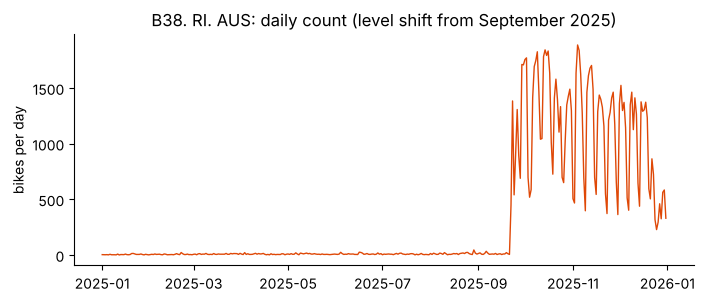

outlier flags at this site: 10 of 10 in total


In [2]:
b38 = valid[valid["site_name"] == "B38. RI. AUS"]
monthly = b38.groupby(b38["date"].dt.month)["bikes_total"].mean().round(0)
print("Mean bikes per day by month:")
print(monthly.to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(b38["date"], b38["bikes_total"], color="#DF4807", lw=1)
ax.set_title("B38. RI. AUS: daily count (level shift from September 2025)")
ax.set_ylabel("bikes per day")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("outlier flags at this site:", int(m.loc[m["site_name"] == "B38. RI. AUS", "is_outlier"].sum()),
      "of", int(m["is_outlier"].sum()), "in total")

## 2. Effects per site (median across sites)

In [3]:
v = valid[valid["site_name"] != "B38. RI. AUS"].copy()
working = ~v["is_weekend"] & ~v["is_holiday"]
dry = ~v["is_rainy"]

def effect(group, baseline):
    """Per site: mean(group) / mean(baseline) - 1. Returns the median and IQR across sites (in %)."""
    ratios = []
    for _, g in v.groupby("site_id"):
        a = g.loc[group.loc[g.index], "bikes_total"]
        b = g.loc[baseline.loc[g.index], "bikes_total"]
        if len(a) >= 5 and len(b) >= 5 and b.mean() > 0:
            ratios.append(a.mean() / b.mean() - 1)
    r = np.array(ratios) * 100
    return round(np.median(r)), round(np.percentile(r, 25)), round(np.percentile(r, 75)), len(r)

rows = {
    "Rain >= 1 mm vs dry (working days)": effect(v["is_rainy"] & working, dry & working),
    "Heavy rain >= 10 mm vs dry (working days)": effect((v["precip_mm"] >= 10) & working, dry & working),
    "Cold < 5 °C vs warm > 15 °C (dry working days)": effect((v["temp_mean_c"] < 5) & working & dry,
                                                            (v["temp_mean_c"] > 15) & working & dry),
    "Weekend vs working day": effect(v["is_weekend"] & ~v["is_holiday"], working),
    "Public holiday vs working day": effect(v["is_holiday"], working),
}
effects = pd.DataFrame(rows, index=["median %", "Q1 %", "Q3 %", "sites"]).T
effects

,median %,Q1 %,Q3 %,sites
Rain >= 1 mm vs dry (working days),-14,-15,-12,29
Heavy rain >= 10 mm vs dry (working days),-23,-25,-20,29
Cold < 5 °C vs warm > 15 °C (dry working days),-35,-42,-30,29
Weekend vs working day,-40,-46,-34,29
Public holiday vs working day,-52,-57,-49,29


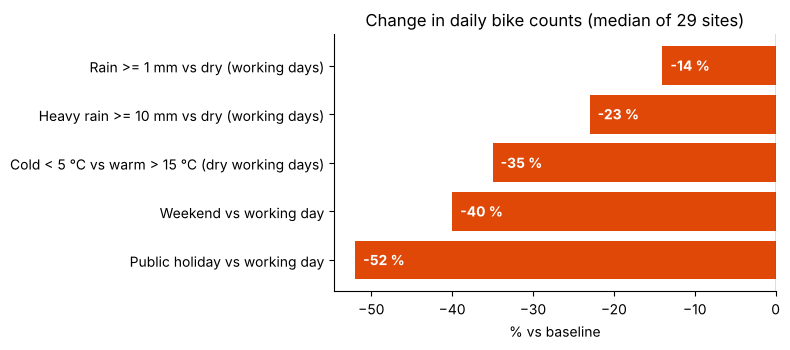

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
e = effects.sort_values("median %")
ax.barh(e.index, e["median %"], color="#DF4807")
for i, val in enumerate(e["median %"]):
    ax.text(val + 1, i, f"{val:+.0f} %", va="center", ha="left", color="white", fontweight="bold")
ax.axvline(0, color="#575756", lw=1)
ax.set_title("Change in daily bike counts (median of 29 sites)")
ax.set_xlabel("% vs baseline")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. How much do these four features explain?

In [5]:
v["relative"] = v["bikes_total"] / v.groupby("site_id")["bikes_total"].transform("mean")
X = v[["temp_mean_c", "precip_mm", "is_weekend", "is_holiday"]].astype(float).assign(intercept=1.0)
beta, *_ = np.linalg.lstsq(X.values, v["relative"].values, rcond=None)
pred = X.values @ beta
r2 = 1 - ((v["relative"] - pred) ** 2).sum() / ((v["relative"] - v["relative"].mean()) ** 2).sum()
print(f"R² (temperature, rain, weekend, holiday; counts normalised per site): {r2:.2f}")
print(pd.Series(beta, index=X.columns).round(3).to_string())

R² (temperature, rain, weekend, holiday; counts normalised per site): 0.57
temp_mean_c    0.024
precip_mm     -0.016
is_weekend    -0.472
is_holiday    -0.547
intercept      0.890


## Result

**Calendar beats weather:** public holidays −52 %, weekends −40 %, cold days −35 %, heavy rain −23 %, rain −14 % (median across 29 sites). Temperature, rain, weekend and holiday together explain **57 %** of the daily variation, so the cleaned `model_table` is a usable basis for a forecasting model, as long as outage days, missing days and the B38. RI. AUS period before September are left out.